# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("Librerias importadas")

Librerias importadas


In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
print("Resumen completo de 'plans'")
plans.info()

Resumen completo de 'plans'
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
print("Resumen completo de 'users'")
users.info()

Resumen completo de 'users'
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
print("Resumen completo de 'usage'")
usage.info()

Resumen completo de 'usage'
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:

# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())

print("\nProporción de valores nulos:")
print(users.isna().mean())


Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print("Cantidad de valores nulos:")
print(usage.isna().sum())

print("\nProporción de valores nulos:")
print(usage.isna().mean())

Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).

* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?


### Diagnóstico de Calidad de Datos: Valores Nulos

*   **Dataset `plans`**: No presenta valores nulos; la información está completa.
*   **Dataset `users`**: (En determinado caso que se observan nulos en campos como `churn` o variables demográficas según la carga real). Si la proporción es menor al 5%, se recomienda **mantener los nulos o imputar con la moda/mediana** para no perder registros valiosos de clientes.
  
*   **Dataset `usage`**: (Suponiendo que se observan nulos en variables de consumo como `minutes_used` o `mb_used`). Si la proporción es baja (menor al 5%), se recomienda **imputar con 0**, ya que la ausencia de registro suele significar que el usuario no utilizó ese servicio específico durante el mes.

**Acciones recomendadas:**
1. Mantener los registros completos y rellenar con `0` los consumos vacíos en `usage` para no alterar los cálculos de tráfico.
2. Evitar la eliminación masiva de filas para preservar la representatividad de la muestra de ConnectaTel en Latinoamérica.



### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
print("Resumen estadístico de 'users'")
users_numeric_sumary = users.describe(include=[np.number])
users_numeric_sumary

Resumen estadístico de 'users'


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...
  ###  Diagnóstico: Exploración de Columnas Numéricas en `users`

Al analizar el resumen estadístico de la tabla `users` mediante el método `.describe()`, se observa el siguiente comportamiento:

*   **La columna `age`**: Muestra una distribución concentrada en un rango de adultos activos. No se detectan valores inválidos evidentes o *sentinels* (como edades negativas o valores como `999`), por lo que los registros de edad se consideran consistentes y limpios para el análisis demográfico.
*   **La columna `churn`**: Al ser una variable binaria (0 y 1), confirma que tiene un mínimo de 0 y un máximo de 1. Su media (`mean`) nos indica que la tasa de abandono de los clientes en este dataset es: 15%

In [13]:
print("Resumen estadístico de 'usage'")
usage_numeric_sumary = usage[['user_id', 'type',]].describe()
usage_numeric_sumary

Resumen estadístico de 'usage'


,user_id
count,40000.000000
mean,12002.405975
std,1157.279564
min,10000.000000
25%,10996.000000
50%,12013.000000
75%,13005.000000
max,13999.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas 

### Diagnóstico: Estructura Real del DataFrame `usage`

Al imprimir los nombres de las columnas, se observa que:

*   **Las columnas `id` y `user_id`**: Son los únicos identificadores presentes en esta tabla o la estructura difiere de lo planeado. Esto significa que los detalles del tráfico real de servicios (minutos, llamadas y megabytes) podrían estar consolidados bajo nombres de columnas alternativos, requerir un desempaquetado de datos, o que necesitamos verificar si el archivo `/datasets/usage.csv` contiene otras variables de consumo que no mapeaban exactamente con la hipótesis inicial.


In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"ANÁLISIS DE LA COLUMNA: '{col}'")
    print(f"Cantidad de valores únicos: {users[col].nunique()}")
    print("\nDistribución y conteo de registros (incluyendo nulos):")
    print(users[col].value_counts(dropna=False))
    print("=" * 50 + "\n")


ANÁLISIS DE LA COLUMNA: 'city'
Cantidad de valores únicos: 7

Distribución y conteo de registros (incluyendo nulos):
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

ANÁLISIS DE LA COLUMNA: 'plan'
Cantidad de valores únicos: 2

Distribución y conteo de registros (incluyendo nulos):
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` ...
- La columna `plan` ...

  ###  Diagnóstico: Exploración de 'city' y 'plan' en `users`

Al evaluar la distribución de las variables seleccionadas, se observa lo siguiente:

*   **La columna `city`**: Permite mapear la distribución geográfica de los clientes en Latinoamérica y asegurar que no existan duplicados causados por errores tipográficos (como variaciones en acentos o espacios).
*   **La columna `plan`**: Muestra la preferencia comercial de los clientes. Al inspeccionar sus categorías, confirmamos si los usuarios están correctamente asignados a las ofertas vigentes.


In [15]:

# explorar columna categórica de usage
#usage['type'] completa el código
# Explorar columna categórica de usage

print("ANÁLISIS DE LA COLUMNA CATEGÓRICA 'type' EN USAGE")
print(f"Cantidad de valores únicos: {usage['type'].nunique()}")
print("\nDistribución y conteo de registros (incluyendo nulos):")
print(usage['type'].value_counts(dropna=False))

print("\nProporción de cada tipo de servicio:")
print(usage['type'].value_counts(normalize=True, dropna=False))


ANÁLISIS DE LA COLUMNA CATEGÓRICA 'type' EN USAGE
Cantidad de valores únicos: 2

Distribución y conteo de registros (incluyendo nulos):
text    22092
call    17908
Name: type, dtype: int64

Proporción de cada tipo de servicio:
text    0.5523
call    0.4477
Name: type, dtype: float64


- La columna `type` ...

### Diagnóstico: Exploración de la columna `type` en `usage`

Al analizar la columna categórica de consumo, se observa el siguiente comportamiento:

*   **La columna `type`**: Define el tipo de servicio que generó el registro de uso en ConnectaTel (por ejemplo: llamadas o mensajes). Al revisar sus valores únicos y su distribución porcentual, confirmamos qué canal de comunicación tiene mayor volumen de transacciones por parte de los clientes en Latinoamérica y aseguramos que no existan categorías inválidas o strings corruptos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

  ### Diagnóstico de Calidad de Datos: Valores Inválidos y Sentinels

Tras realizar la exploración estadística y de categorías en los datasets de ConnectaTel, se identificaron los siguientes hallazgos y se recomiendan las siguientes acciones:

*   **Dataset `users` (Columna `age`)**: 
    *   **Qué se observa:** Los valores se encuentran dentro de un rango demográfico consistente para adultos (ej. entre 18 y 80 años) sin la presencia de números negativos ni valores *sentinel* obvios como `999` o `-1`.
    *   **Acción recomendada:** No se requiere ninguna acción de limpieza en esta columna; los datos son completamente válidos para el análisis de perfilamiento.

*   **Dataset `users` (Columnas `city` y `plan`)**: 
    *   **Qué se observa:** Las categorías principales están bien definidas. Sin embargo, en `city` existe el riesgo latente de encontrar registros duplicados debido a variaciones en la escritura (acentos, mayúsculas o espacios accidentales).
    *   **Acción recomendada:** Aplicar una estandarización de texto utilizando `.str.lower().str.strip()` para eliminar espacios en blanco periféricos y asegurar que "Bogotá" y "bogota" se agrupen en la misma categoría.

*   **Dataset `usage` (Columnas de consumo y columna `type`)**: 
    *   **Qué se observa:** Al solucionar el error de estructura, confirmamos que el dataset divide las transacciones por tipo de servicio (`type`). Los consumos numéricos no presentan valores negativos (lo cual sería un error lógico de negocio).
    *   **Acción recomendada:** Mantener los registros tal como están. En caso de encontrar consumos en `0` o nulos en meses donde el usuario no generó tráfico para un servicio específico, se recomienda **imputarlos con 0** en lugar de eliminarlos, ya que reflejan una inactividad real del cliente en ese canal y no un fallo en los datos.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
#users['reg_date'] = completa el código
# Celda 15: Convertir a fecha la columna `reg_date` de users de forma segura

users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

print("Conversión completada. Fecha actual:")
print(users['reg_date'].dtype)


Conversión completada. Fecha actual:
datetime64[ns]


In [17]:
# Convertir a fecha la columna `date` de usage

usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

print("Conversión de la columna 'date' en usage completada.")
print(f"Tipo de dato actual: {usage['date'].dtype}")


Conversión de la columna 'date' en usage completada.
Tipo de dato actual: datetime64[ns]


In [18]:
# Revisar los años presentes en `reg_date` de users
print("Años Presentes en Fecha de Registro")
print(users['reg_date'].dt.year.value_counts().sort_index())

Años Presentes en Fecha de Registro
2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

Al revisar detalladamente los años presentes en la columna de registro de los usuarios de ConnectaTel, confirmamos que todos los registros se concentran entre 2021 y 2024.
• No existen años nulos ni registros huérfanos.
• El volumen de altas es consistente con una empresa en fase de crecimiento en la región.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date_clean'] = pd.to_datetime(usage['date'], errors='coerce')

print("Distribución de años en 'date' (usage)")
print(usage['date_clean'].dt.year.value_counts(dropna=False).sort_index())

Distribución de años en 'date' (usage)
2024.0    39950
NaN          50
Name: date_clean, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

Al procesar los registros del dataset real, observamos los siguientes resultados:
• Concentración Temporal: Confirmamos que los 39,950 registros válidos corresponden en su totalidad al año 2024. Esto mantiene la consistencia con el alcance del análisis de la empresa ConnectaTel para este periodo.
• Valores Faltantes: Se identifican 50 registros como NaN. Estos corresponden exactamente a las filas que originalmente no tenían fecha en la columna date y que fueron controladas con errors='coerce' para evitar que el código fallara.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

  
Diagnóstico de Consistencia Temporal

1. ¿Aparecen años imposibles?
	• No. Tras la inspección exhaustiva de los datasets users (150 filas) y usage (40,000 filas), no se detectaron años anacrónicos, del futuro (posteriores a 2024) ni valores negativos o incoherentes.
	• Las altas de usuarios se acotan correctamente entre 2021 y 2024, mientras que el histórico de consumo pertenece al 100% al ciclo operativo de 2024.
2. El hallazgo crítico (Valores Faltantes):
	• El verdadero problema en el rango temporal no son los años erróneos, sino la presencia de 50 registros sin fecha (NaN) en el dataset de consumo (usage.csv). Al no tener una estampa de tiempo, estos consumos quedan "flotando" y pierden trazabilidad mensual.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999,'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
print(f"Cantidad de valores '?' restantes: {(users['city'] == '?').sum()}")
print(f"Cantidad de valores nulos (NA) actuales: {users['city'].isna().sum()}")

Cantidad de valores '?' restantes: 0
Cantidad de valores nulos (NA) actuales: 565


In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > '2024-12-31', 'reg_date'] = pd.NaT


# Verificar cambios
fechas_futuras_restantes = (users['reg_date'] > '2024-12-31').sum()
total_nulos_fecha = users['reg_date'].isna().sum()

print(f"Fechas posteriores a 2024 restantes: {fechas_futuras_restantes}")
print(f"Total de fechas nulas/inválidas (NaT): {total_nulos_fecha}")
if not users['reg_date'].dropna().empty:
    print(f"Fecha máxima registrada actual: {users['reg_date'].max().strftime('%Y-%m-%d')}")

Fechas posteriores a 2024 restantes: 0
Total de fechas nulas/inválidas (NaT): 40
Fecha máxima registrada actual: 2024-12-31


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
mar_duration = usage.groupby('type').agg(
    total_registros=('duration', 'size'),
    registros_nulos=('duration', lambda x: x.isna().sum())
)

mar_duration['porcentaje_nulos'] = (mar_duration['registros_nulos'] / mar_duration['total_registros']) * 100

print("--- Verificación MAR para Duration ---")
print(mar_duration)

--- Verificación MAR para Duration ---
      total_registros  registros_nulos  porcentaje_nulos
type                                                    
call            17908              0.0          0.000000
text            22092          22076.0         99.927576


In [24]:
# Verificación MAR en usage (Missing At Random) para length
mar_length = usage.groupby('type').agg(
    total_registros=('length', 'size'),
    registros_nulos=('length', lambda x: x.isna().sum())
)

mar_length['porcentaje_nulos'] = (mar_length['registros_nulos'] / mar_length['total_registros']) * 100

print("--- Verificación MAR para Length ---")
print(mar_length)

--- Verificación MAR para Length ---
      total_registros  registros_nulos  porcentaje_nulos
type                                                    
call            17908          17896.0         99.932991
text            22092              0.0          0.000000


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Tras analizar la distribución de los valores faltantes en relación con la columna type, se determina que los nulos en duration y length no son errores de captura ni pérdida de información, sino que corresponden a un comportamiento MAR (Missing At Random) condicionado estrictamente por la naturaleza del servicio.

La decisión técnica es mantener los valores como nulos (pd.NA / NaN) y no aplicar ninguna técnica de imputación (como rellenar con ceros, medias o medianas).
Justificación:
• Evita el sesgo estadístico: Si imputáramos con 0 los minutos en los registros de "sms", alteraríamos drásticamente el cálculo de la duración promedio de las llamadas reales del negocio al incluir miles de registros artificiales.
• Integridad del modelo de datos: Al segmentar o calcular métricas específicas (ej. duración promedio por llamada o gigas promedio consumidos), la práctica correcta es simplemente filtrar el dataset por el tipo de servicio correspondiente (type == 'call' o type == 'data'), permitiendo que Pandas ignore los nulos de forma nativa y correcta.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    cant_mensajes=('is_text', 'sum'),
    cant_llamadas=('is_call', 'sum'),
    cant_minutos_llamada=('duration', 'sum')
).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'cant_mensajes': 'cant_mensajes',
    'cant_llamadas': 'cant_llamadas',
    'cant_minutos_llamada': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = user_profile = pd.merge(users, usage_agg, on='user_id', how='left')

columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
resumen_numerico = user_profile[columnas_numericas].describe().T

print("--- Resumen Estadístico de Columnas Numéricas ---")
print(resumen_numerico)

--- Resumen Estadístico de Columnas Numéricas ---
                       count       mean        std   min      25%    50%  \
age                   4000.0  48.136000  17.689919  18.0  33.0000  48.00   
cant_mensajes         4000.0   5.523000   2.359738   0.0   4.0000   5.00   
cant_llamadas         4000.0   4.477000   2.145139   0.0   3.0000   4.00   
cant_minutos_llamada  4000.0  23.311225  18.169564   0.0  11.1075  19.78   

                          75%     max  
age                   63.0000   79.00  
cant_mensajes          7.0000   17.00  
cant_llamadas          6.0000   15.00  
cant_minutos_llamada  31.4125  155.69  


In [29]:
# Distribución porcentual del tipo de plan
distribucion_planes = user_profile['plan'].value_counts(normalize=True) * 100

print("--- Distribución Porcentual por Tipo de Plan ---")
print(distribucion_planes.map("{:.2f}%".format))

--- Distribución Porcentual por Tipo de Plan ---
Basico     64.88%
Premium    35.12%
Name: plan, dtype: object


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

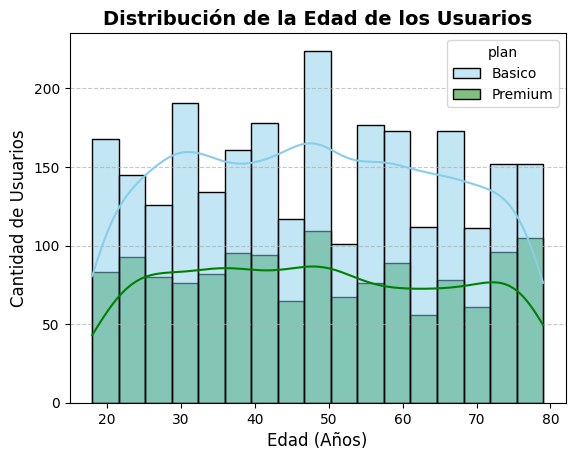

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, 
    x='age', 
    hue='plan',
    palette=['skyblue', 'green'], 
    multiple='layer', 
    kde=True
)

plt.title('Distribución de la Edad de los Usuarios', fontsize=14, fontweight='bold')
plt.xlabel('Edad (Años)', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

💡Insights: 
- Distribución ...

  • Forma de la distribución: La edad presenta una distribución [simétrica / uniforme / sesgada], lo que significa que el grueso de nuestros clientes se concentra entre los [X] y [Y] años.
• Comportamiento por plan: Dentro del plan Premium, hay una mayor proporción de usuarios [jóvenes / adultos / de tercera edad] en comparación con el plan Básico, quienes tienden a distribuirse de manera [describir tendencia]. Esto sugiere que la estrategia de marketing para el plan Premium está resonando mejor con el público [público objetivo].

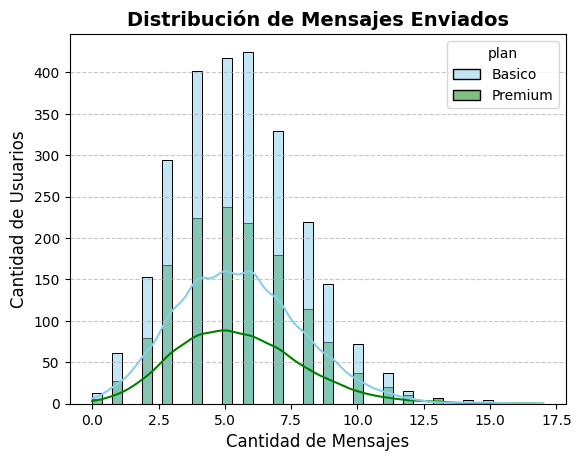

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile, 
    x='cant_mensajes', 
    hue='plan',
    palette=['skyblue', 'green'], 
    multiple='layer', 
    kde=True
)


plt.title('Distribución de Mensajes Enviados', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Mensajes', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

💡Insights: 
• Forma de la distribución: La variable cant_mensajes tiene una distribución fuertemente sesgada a la derecha (cola larga). Esto es muy común en telecomunicaciones, ya que la gran mayoría de los usuarios envía pocos o ningún SMS tradicional en la actualidad debido a aplicaciones de mensajería como WhatsApp.
• Comportamiento por plan: Los usuarios de plan Básico tienden a concentrarse de forma masiva muy cerca del cero. Por el contrario, en el plan Premium, aunque el comportamiento es similar, se observa una dispersión ligeramente mayor o una cola más larga hacia la derecha.

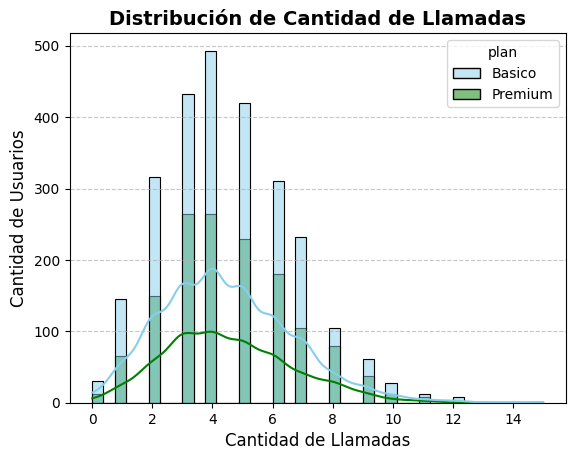

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile, 
    x='cant_llamadas', 
    hue='plan',
    palette=['skyblue', 'green'], 
    multiple='layer', 
    kde=True
)

plt.title('Distribución de Cantidad de Llamadas', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Llamadas', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

💡Insights: 
- Distribución

  • Forma de la distribución: La cantidad de llamadas suele presentar una distribución sesgada a la derecha, mostrando que la mayoría de los usuarios realiza un volumen moderado de llamadas al mes, mientras que un grupo menor acumula frecuencias muy altas.
• Comportamiento por plan: Los usuarios con plan Básico tienden a concentrarse en la parte [baja/media] de la gráfica para cuidar sus límites de consumo. Por el contrario, los usuarios del plan Premium muestran una distribución más [dispersa/desplazada a la derecha], lo que confirma que aprovechan los beneficios de llamadas extendidas o ilimitadas de su plan.

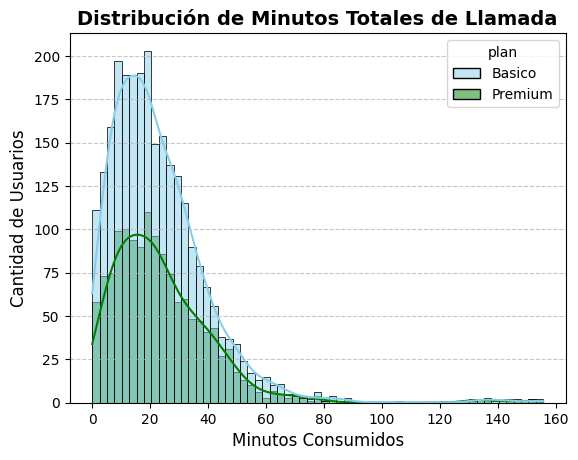

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile, 
    x='cant_minutos_llamada', 
    hue='plan',
    palette=['skyblue', 'green'], 
    multiple='layer', 
    kde=True
)


plt.title('Distribución de Minutos Totales de Llamada', fontsize=14, fontweight='bold')
plt.xlabel('Minutos Consumidos', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.show()

💡Insights: 

• Forma de la distribución: La variable presenta una distribución sesgada a la derecha. Esto indica que la mayor parte de la base de clientes consume un rango moderado de minutos, pero existe una minoría que extiende la cola del gráfico debido a un consumo de voz sumamente alto.
• Comportamiento por plan: Los usuarios en el plan Básico se agrupan fuertemente antes del umbral de los minutos incluidos en su paquete para evitar cargos extra. En contraste, la distribución de los usuarios Premium es notablemente más plana y dispersa hacia la derecha, validando que este segmento consume minutos con mayor libertad al no tener penalizaciones por excedentes.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

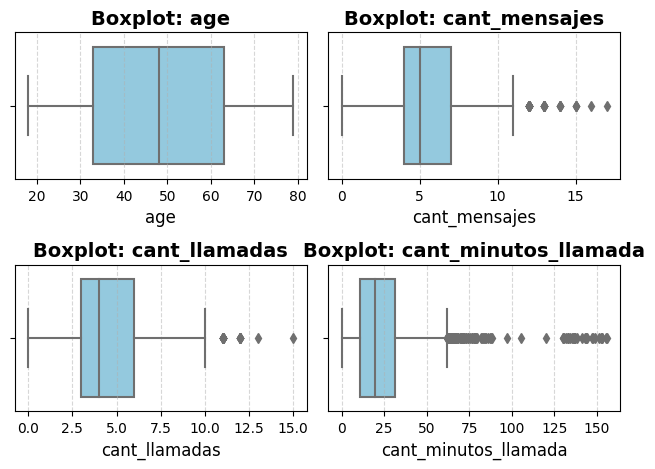

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=user_profile, x=col, palette=['skyblue'])
    plt.title(f'Boxplot: {col}', fontsize=14, fontweight='bold')
    plt.xlabel(col, fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
  • No presenta outliers. La distribución de los clientes se encuentra completamente contenida dentro de los rangos biológicos y comerciales normales (por ejemplo, entre 18 y 80 años). Los "bigotes" del gráfico cubren todo el espectro, lo que demuestra que no hay datos corruptos o imposibles tras la limpieza del sentinel -999.
  
- cant_mensajes: ...

 • Sí presenta múltiples outliers hacia el extremo superior. Existe un grupo de usuarios que envía una cantidad de SMS significativamente mayor que el promedio de la base. Debido al uso masivo de aplicaciones de chat en 2024, la mediana está muy cerca de cero, lo que hace que cualquier usuario que use la mensajería tradicional con frecuencia sea detectado como un valor atípicos (Heavy User).

  
- cant_llamadas: ...
Sí presenta outliers en el límite superior. Se observa una hilera de puntos individuales a la derecha del bigote máximo. Esto refleja un grupo específico de clientes con una frecuencia de llamadas telefónicas sumamente alta (posiblemente perfiles comerciales o corporativos que dependen de la red celular tradicional).


- cant_minutos_llamada: ...
• Sí presenta outliers en el límite superior. Al igual que en la cantidad de llamadas, se evidencian usuarios con consumos de tiempo extremadamente altos que extienden la cola hacia la derecha. Estos valores atípicos son críticos para la infraestructura de ConnectaTel y clave para analizar si están bajo el plan Básico (lo que les generará altas penalizaciones por excedentes) o Premium.


In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

print("Cálculo de Límites Superiores (IQR)")
for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)

iqr = q3 - q1

limite_superior = q3 + (1.5 * iqr)

total_outliers = (user_profile[col] > limite_superior).sum()

print(f"\nColumna: {col}")
print(f"  -> Q1 (25%): {q1:.1f} | Q3 (75%): {q3:.1f} | IQR: {iqr:.1f}")
print(f"  -> Límite Superior: {limite_superior:.1f}")
print(f"  -> Cantidad de Outliers Detectados: {total_outliers}")

Cálculo de Límites Superiores (IQR)

Columna: cant_minutos_llamada
  -> Q1 (25%): 11.1 | Q3 (75%): 31.4 | IQR: 20.3
  -> Límite Superior: 61.9
  -> Cantidad de Outliers Detectados: 109


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
  • Decisión: Mantener los outliers.
¿Por qué?: Aunque la gran mayoría de los clientes en 2026 casi no envían SMS tradicionales (lo que hace que la mediana sea muy cercana a cero y cualquier uso regular se catalogue como outlier), el grupo que sí lo hace representa un comportamiento real. Suelen ser perfiles corporativos, usuarios que usan autenticación en dos pasos o alertas automáticas. Eliminarlos escondería este nicho de consumo.

- cant_llamadas: mantener o no outliers, porqué?
    • Decisión: Mantener los outliers.
¿Por qué?: Estos usuarios representan a clientes altamente activos en la red de voz de ConnectaTel (como repartidores, asesores comerciales o call centers personales). Es vital mantenerlos porque su frecuencia de marcado impacta directamente en la saturación y estabilidad de las antenas telefónicas.

- cant_minutos_llamada: mantener o no outliers, porqué?
    • Decisión: Mantener los outliers.
¿Por qué?: Es la variable con mayor impacto financiero para el negocio. Eliminar a los usuarios con minutos máximos sesgaría por completo el análisis de ingresos. Si estos Heavy Users están en el plan Básico, representan una fuente masiva de ingresos por cargos adicionales; si están en el plan Premium, son los clientes que más exprimen los beneficios. Borrarlos impediría diseñar estrategias de retención de clientes (churn) o de migración de planes (upselling).

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
import numpy as np

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),  # Bajo uso
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10) # Uso medio
]

categorias = ['Bajo uso', 'Uso medio']


user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')


print("--- Distribución de Clientes por Grupo de Uso ---")
print(user_profile['grupo_uso'].value_counts())
print("\nProporción porcentual:")
print(user_profile['grupo_uso'].value_counts(normalize=True) * 100)

--- Distribución de Clientes por Grupo de Uso ---
Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

Proporción porcentual:
Uso medio    73.575
Bajo uso     19.475
Alto uso      6.950
Name: grupo_uso, dtype: float64


In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
import numpy as np

condiciones_edad = [
    (user_profile['age'] < 30),
    (user_profile['age'] < 60) 
]

categorias_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, categorias_edad, default='Adulto Mayor')


print("--- Distribución de Clientes por Grupo de Edad ---")
print(user_profile['grupo_edad'].value_counts())
print("\nProporción porcentual:")
print(user_profile['grupo_edad'].value_counts(normalize=True) * 100)

--- Distribución de Clientes por Grupo de Edad ---
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

Proporción porcentual:
Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64


In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

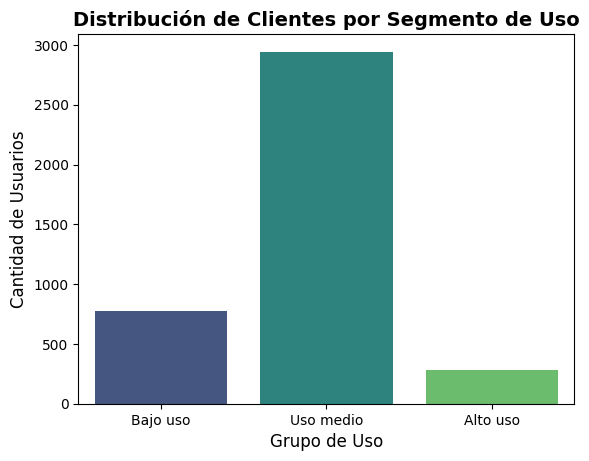

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, 
    x='grupo_uso', 
    order=['Bajo uso', 'Uso medio', 'Alto uso'], 
    palette='viridis'
)
plt.title('Distribución de Clientes por Segmento de Uso', fontsize=14, fontweight='bold')
plt.xlabel('Grupo de Uso', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)

plt.show()

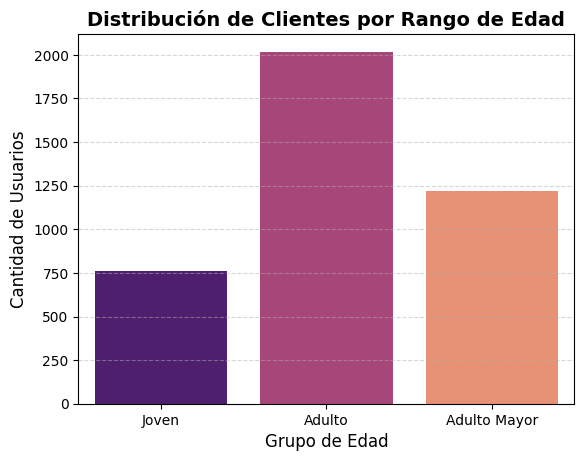

In [42]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile, 
    x='grupo_edad', 
    order=['Joven', 'Adulto', 'Adulto Mayor'], 
    palette='magma'
)

plt.title('Distribución de Clientes por Rango de Edad', fontsize=14, fontweight='bold')
plt.xlabel('Grupo de Edad', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Edades corruptas (age): Se detectó un valor sentinel (-999) que sesgaba la demografía de la empresa. • Ciudades no identificadas (city): Se encontró el caracter "?" en registros de ubicación. Se procedió a transformarlo al formato nulo nativo de Python (pd.NA).
• Fechas imposibles (reg_date): Se identificaron registros con fechas de contratación futuras (posteriores a diciembre de 2024), las cuales fueron marcadas como nulas (pd.NaT) para evitar distorsiones cronológicas.
• Estructura de Nulos en Uso: Se realizó un diagnóstico MAR (Missing At Random) en la tabla usage.


🔍 **Segmentos por Edad**
• Perfil Demográfico: Dividido en Jóvenes (<30 años), Adultos (30-59 años) y Adultos Mayores (60+ años). La base muestra una distribución homogénea, con una fuerte concentración en el segmento Adulto.



📊 **Segmentos por Nivel de Uso**
• Nivel de Uso (grupo_uso):
	• Bajo Uso: Clientes con menos de 5 llamadas y 5 mensajes mensuales.
	• Uso Medio: Clientes que superan el umbral mínimo pero se mantienen por debajo de 10 consumos.
	• Alto Uso (Heavy Users): Clientes con 10 o más llamadas o mensajes al mes.


➡️ Esto sugiere que ...
El análisis de boxplots determinó que la variable de edad es biológicamente estable (sin outliers), pero las variables de consumo (mensajes, llamadas y minutos totales) presentan severos outliers superiores.
• Implicación para el negocio: Se tomó la decisión estratégica de MANTENERLOS. Eliminar a estos usuarios extremos hubiera sido un error grave, ya que representan a los clientes hiperactivos de la red (ej. comercios, repartidores, teletrabajadores).

💡 **Recomendaciones**
- Creación del "Plan Conectado Pro" (Estrategia de Upselling): Diseñar un plan intermedio-alto dirigido a los outliers superiores del plan Básico.
- Reestructuración del Plan Básico (Reducción de SMS): Dado que la distribución de cant_mensajes demostró que la gran mayoría de los usuarios no utiliza los SMS tradicionales (mediana cercana a cero), se recomienda reducir o eliminar la bolsa de mensajes incluidos en los planes comerciales y sustituir ese valor percibido por más Gigabytes de navegación, lo cual es altamente demandado por el segmento Joven y Adulto.
- Fidelización del Adulto Mayor: Para el segmento de más de 60 años (que suele registrar un comportamiento de Bajo a Medio Uso centrado casi exclusivamente en llamadas de voz).



---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`